In [1]:
import numpy as np
import mbtr.utils as ut
from scipy.linalg import hankel
from scipy.stats import expon
import matplotlib.pyplot as plt
from mbtr.mbtr import MBT
from mbtr.utils import set_figure
from mbtr import LOSS_MAP
from ExpLoss import JointExpLikelihood

LOSS_MAP['joint exponential'] = JointExpLikelihood # this line has to be added for the MBT class to recognize the JointExpLikelihood subclass as a type of loss

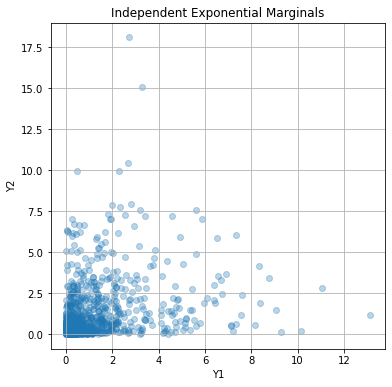

In [2]:
np.random.seed(42)

n = 100000

x = np.random.uniform(0, 1, n)

groupA = (x<0.5)
groupB = ~groupA

rate1 = np.zeros(n)
rate2 = np.zeros(n)

rate1[groupA] = 0.5
rate2[groupA] = 0.5

rate1[groupB] = 3
rate2[groupB] = 3

y1 = np.random.exponential(scale=1/rate1, size = n)
y2 = np.random.exponential(scale=1/rate2, size = n)

plt.figure(figsize=(6, 6))
plt.scatter(y1[:1000], y2[:1000], alpha=0.3)
plt.title("Independent Exponential Marginals")
plt.xlabel("Y1")
plt.ylabel("Y2")
plt.grid(True)
plt.show()

In [17]:
x = x.reshape(-1,1)
y = np.vstack((y1, y2)).T
m = MBT(loss_type = "joint exponential", n_boosts = 20, min_leaf = 1000, refit=False, lambda_weights=0, lambda_leaves=0, learning_rate=0.5).fit(x, y, do_plot=False)

100%|██████████| 20/20 [05:05<00:00, 15.27s/it]


#---------------- Model fitted in 5.09e+00 min ----------------


In [18]:
tpar = m.predict(x)
par = np.hstack((np.exp(tpar[:,0].reshape(-1, 1)), np.exp(tpar[:,1].reshape(-1,1))))

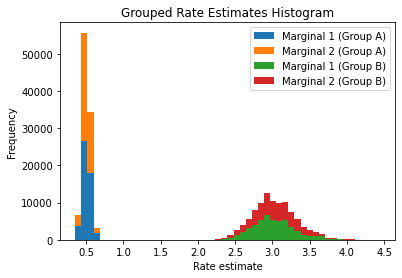

In [19]:
plt.hist([par[groupA, 0], par[groupA, 1], par[groupB, 0], par[groupB, 1]], stacked = True, label = ["Marginal 1 (Group A)", "Marginal 2 (Group A)", "Marginal 1 (Group B)", "Marginal 2 (Group B)"], bins = 50)
plt.xlabel("Rate estimate")
plt.ylabel("Frequency")
plt.title("Grouped Rate Estimates Histogram")
plt.legend()
plt.show()